# Entrega 2 — Descripción del dataset y origen (versión corregida)

**Proyecto:** anticipar qué divisiones de la industria manufacturera argentina van a estar en contracción interanual **3 meses después del momento de la predicción**.
**Alumna:** Mónica Frías — Aprendizaje Automático, 2026.

Este notebook hace todo lo necesario antes de entrenar modelos:

1. Carga los archivos originales tal como se descargaron (INDEC y BCRA) y muestra por qué no se pueden usar directamente.
2. Aplica las transformaciones (código del módulo `contraccion_industrial/`) y arma la tabla **división × mes**.
3. Describe el dataset final: instancias, columnas, tipos y **tratamiento de faltantes**.
4. Analiza la variable objetivo.
5. Implementa la **disponibilidad temporal** de los datos y el **horizonte de predicción**.
6. Define el modelo de referencia.
7. Explora la relación entre las predictoras y la variable objetivo, **usando solo el período de entrenamiento**.
8. Prepara las entradas para los modelos (**escalado** aprendido solo con el entrenamiento de cada corte).

La documentación completa (fuentes, enlaces, fechas de descarga y limitaciones) está en [`docs/02_descripcion_dataset_y_origen.md`](../docs/02_descripcion_dataset_y_origen.md), el diccionario de datos en [`references/diccionario_de_datos.md`](../references/diccionario_de_datos.md), y las dependencias y la estructura del proyecto en el [`README`](../README.md).

### Cambios respecto de la primera versión (devolución de la Entrega 2)

| Punto de la devolución | Qué se cambió | Dónde |
|---|---|---|
| Horizonte de predicción | El objetivo pasa de *t+3* a **t+5 frente a t-7**: con la decisión en *t+2*, el mes predicho queda 3 meses después. Se actualizaron la disponibilidad de etiquetas y las particiones. | `contraccion_industrial/config.py` y `features.py`, secciones 2 y 5 |
| Faltantes | Se **excluyen** los primeros meses sin historia suficiente (sin imputar) y se verifica que no quede ninguno. | `contraccion_industrial/modeling/particiones.py`, sección 3 |
| Escalado | Escalado dentro de un `Pipeline`, ajustado solo con el entrenamiento de cada corte. Los extremos de la pandemia no se recortan. | `contraccion_industrial/modeling/preprocesamiento.py`, sección 8 |
| Variaciones interanuales | Se corrigió la afirmación: no eliminan con garantía la estacionalidad ni convierten series nominales en reales. | sección 2 y `docs/02` |
| Quintiles | Se reemplazó `rank(method="first")`: los cortes se calculan sobre los valores originales, con una observación por mes para las variables macro. | sección 7 |
| Documentación | Capacidad de papel e impresión aclarada como aproximación propia; dependencias y versiones agregadas. | sección 2 y `docs/02` |
| Organización del repositorio | Estructura según la plantilla Cookiecutter Data Science: el código pasa de `src/` al módulo `contraccion_industrial/`, se agregan `docs/`, `models/`, `reports/figures/` y `data/interim/`, y el notebook sigue la convención de nombres de la plantilla. | README |


In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PARCIAL = Path("..").resolve()          # carpeta Parcial/ (el notebook está en Parcial/notebooks/)
sys.path.append(str(PARCIAL))           # para importar el módulo contraccion_industrial

from contraccion_industrial.config import EXTERNAL, FIGURES, PROCESSED, RAW
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

## 1. Archivos originales

| Archivo | Contenido | Fuente | Período |
|---|---|---|---|
| `sh_ipi_manufacturero_2026.xls` | Índice de producción industrial manufacturero (IPI) por división, base 2004=100 | INDEC | ene-2016 a ago-2026 |
| `sh_capacidad_09_26.xls` | Utilización de la capacidad instalada: nivel general y 12 bloques sectoriales (%) | INDEC | ene-2016 a jul-2026 |
| `balanmensual.xls` | Exportaciones e importaciones mensuales (millones de USD) | INDEC | ene-1990 a sep-2026 |
| `com3500.xls` | Tipo de cambio mayorista de referencia (Com. A 3500), diario | BCRA | mar-2002 a oct-2026 |
| `series.xlsm` | Series monetarias; se usa la hoja *TASAS DE MERCADO* (BADLAR) | BCRA | ene-2003 a oct-2026 |

Los archivos están guardados **sin modificar** en `data/raw/`.

In [2]:
pd.DataFrame([{"archivo": f.name, "tamaño (KB)": round(f.stat().st_size / 1024)}
              for f in sorted(RAW.iterdir()) if f.is_file()])

,archivo,tamaño (KB)
0,balanmensual.xls,192
1,com3500.xls,380
2,series.xlsm,7831
3,sh_capacidad_09_26.xls,56
4,sh_ipi_manufacturero_2026.xls,974


### Cómo vienen los datos

Son planillas pensadas para leer en pantalla, no para procesar: títulos y notas mezclados con los datos, encabezados repartidos en varias filas, el año escrito una sola vez, asteriscos de "dato provisorio" y algunos errores de tipeo. Algunos ejemplos:

**IPI manufacturero (hoja *Cuadro 2*):** los códigos de división están en la fila 2, los nombres en la fila 3, y el año aparece solo en enero.

In [3]:
ipi_crudo = pd.read_excel(RAW / "sh_ipi_manufacturero_2026.xls", sheet_name="Cuadro 2", header=None)
print("Filas x columnas:", ipi_crudo.shape)
ipi_crudo.iloc[:9, :6]

Filas x columnas: (136, 88)


,0,1,2,3,4,5
0,"Cuadro 2. IPI manufacturero nivel general, div...",NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,Código (CLaNAE 2004),NaN,NaN,D,15,15111
3,Período,NaN,NaN,IPI Manufacturero,Alimentos y bebidas,Carne vacuna
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN
6,6,2016,Enero,117.051194,130.676161,83.169668
7,7,NaN,Febrero,118.900294,129.263973,79.919338
8,8,NaN,Marzo,136.80623,141.650623,88.923323


El cuadro tiene muchas más columnas que las 16 divisiones, porque incluye también las subclases. El script se queda solo con las divisiones.

**Capacidad instalada:** el año va en una fila aparte ("Año 2016"), los meses llevan asterisco y al final hay notas al pie.

In [4]:
cap_crudo = pd.read_excel(RAW / "sh_capacidad_09_26.xls", header=None)
cap_crudo.iloc[7:13, :4]

,0,1,2,3
7,Año 2016,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN
9,Enero*,62.9,68.5,83.9
10,Febrero*,64.2,66.8,81.3
11,Marzo*,64.8,67.2,84.1
12,Abril*,64.8,63.5,81.4


**Balanza comercial:** el año lleva asterisco ("2026*") y hay un error de tipeo en el mes de septiembre de 2026.

In [5]:
bal_crudo = pd.read_excel(RAW / "balanmensual.xls", header=None)
bal_crudo.iloc[[474, 480, 481, 482], [0, 1, 2, 7]]

,0,1,2,7
474,2026*,Enero,7245.296047,5056.670157
480,NaN,Julio,8853.859533,6755.731447
481,NaN,Agosto,8865.884766,6706.592916
482,NaN,Septiembree,10035.975188,7059.501178


**Tipo de cambio:** la hoja mensual del BCRA tiene algunas fechas cargadas como texto en lugar de fecha. Por eso se calcula el promedio mensual a partir de la serie **diaria**, que está limpia (y se verifica abajo que coincide con el promedio oficial).

In [6]:
tc_mensual = pd.read_excel(RAW / "com3500.xls", sheet_name="Serie de TCNPM", header=None).iloc[3:, [1, 2]]
fechas_texto = tc_mensual[tc_mensual[1].notna() & pd.to_datetime(tc_mensual[1], errors="coerce").isna()]
print("Filas de la hoja mensual con la fecha escrita como texto:", len(fechas_texto))
fechas_texto.head(3)

Filas de la hoja mensual con la fecha escrita como texto: 10


,1,2
85,Enero-09,3.464
86,Febrero-09,3.5115
87,Marzo-09,3.654


**Tasas de interés:** la hoja *TASAS DE MERCADO* tiene 26 columnas con encabezados de varias filas. Se usa la **BADLAR de bancos privados** (TNA, en %), tasa de referencia para depósitos grandes, que suele usarse como indicador del costo del financiamiento.

In [7]:
tasas_crudo = pd.read_excel(RAW / "series.xlsm", sheet_name="TASAS DE MERCADO", header=None)
encabezados = tasas_crudo.iloc[8].astype(str)
encabezados[encabezados.str.contains("BADLAR")].to_frame("columnas BADLAR disponibles")

,columnas BADLAR disponibles
11,BADLAR (1) - Pesos - Total - TNA
12,BADLAR (1) - Pesos - Bancos\nPrivados - TNA
13,BADLAR (1) - Pesos - Bancos\nPrivados - TEA


## 2. Transformaciones

Todo el preprocesamiento está en el módulo `contraccion_industrial/` (estructura de la plantilla Cookiecutter Data Science), para que se pueda repetir cuando se actualicen los datos. Las rutas y los parámetros compartidos (horizonte, rezago de publicación, lista de predictoras) están en `config.py`.

**`contraccion_industrial/dataset.py`** — IPI a formato largo:
- Toma la hoja *Cuadro 2* y se queda con las 16 divisiones.
- Arma la fecha a partir del año (que aparece solo en enero) y el nombre del mes, sacando los asteriscos.
- Resultado: `data/processed/ipi_divisiones_mensual.csv`, una fila por división y mes.

**`contraccion_industrial/features.py`** — une todo en la tabla de modelado:
1. **Variables del propio IPI:** variación interanual del mes y de los dos meses anteriores, cambio de esa variación en los últimos 3 meses, y si la división está en contracción hoy.
2. **Variable objetivo:** 1 si el IPI del mes *t+5* es menor que el del mismo mes del año anterior (*t-7*). Como la predicción se hace en *t+2* (cuando se publica el IPI de *t*), el mes que se predice queda **3 meses después de la decisión** (sección 5).
3. **Capacidad instalada:** cada división toma la de su bloque sectorial (ver tabla de correspondencia abajo) y además la del nivel general, con un mes de rezago.
4. **Tipo de cambio:** promedio mensual de la serie diaria; se usa la variación interanual y la de 3 meses.
5. **Tasa BADLAR:** promedio mensual de la serie diaria; nivel y diferencia contra un año atrás.
6. **Balanza comercial:** variación interanual de exportaciones e importaciones.
7. **Columnas de disponibilidad temporal:** en qué mes se toma la decisión y en qué mes se conoce el resultado (sección 5).

**Sobre las variaciones interanuales.** Se usan porque comparar cada mes con el mismo mes del año anterior **reduce** parte del efecto estacional (por ejemplo, las vacaciones de enero o la cantidad de días hábiles típicos de cada mes) y pone en una escala comparable series con niveles muy distintos. Pero hay que distinguir tres cosas:

- **Crecimiento interanual** (lo que se usa acá): la variación contra el mismo mes del año anterior. No garantiza eliminar la estacionalidad: si cambian los días hábiles, los feriados o la fecha de Semana Santa, o si la estacionalidad de un sector cambia con los años, el efecto sigue presente.
- **Ajuste estacional**: un procedimiento estadístico específico (como X-13 ARIMA-SEATS, el que usa el INDEC para su serie desestacionalizada) que estima y quita el componente estacional. No se aplicó.
- **Ajuste por precios**: dividir una serie nominal por un índice de precios para expresarla en términos reales. Tampoco se aplicó: `tc_var_ia` es una variación **nominal** del tipo de cambio, y con inflación alta una parte grande de esa variación refleja la suba general de precios y no un cambio del tipo de cambio real. Lo mismo vale para la BADLAR, que es una tasa nominal. Esto se registra como limitación en el README.

El IPI, en cambio, es un índice de **volumen físico** (base 2004 = 100), así que no necesita ajuste por precios.


In [8]:
for script in ["contraccion_industrial.dataset", "contraccion_industrial.features"]:
    resultado = subprocess.run([sys.executable, "-m", script], cwd=PARCIAL,
                               capture_output=True, text=True)
    print(f"===== {script} =====")
    print(resultado.stdout)
    if resultado.returncode != 0:
        print(resultado.stderr)

===== contraccion_industrial.dataset =====
Filas: 2048
Divisiones: 16
Período: 2016-01-01 a 2026-08-01
Valores faltantes: 0
Guardado en: Parcial/data/processed/ipi_divisiones_mensual.csv



===== contraccion_industrial.features =====
Filas totales: 2048
Filas con objetivo y variación interanual: 1776
Período utilizable: 2017-01-01 a 2026-03-01
Proporción de contracción (objetivo=1): 53.9%

Datos faltantes en las filas utilizables:
ipi_var_ia_lag1        16
ipi_var_ia_lag2        32
ipi_var_ia_cambio3m    48
uci_bloque_dif_ia      16
uci_general_dif_ia     16

Etiquetas: {'observada': 1856, 'sin_base': 112, 'pendiente': 80}

Guardado en: Parcial/data/processed/tabla_modelo.csv



### Correspondencia entre divisiones del IPI y bloques de capacidad instalada

El INDEC publica la capacidad instalada en 12 bloques sectoriales, que no coinciden uno a uno con las 16 divisiones del IPI. La correspondencia se definió comparando los nombres y el contenido de cada bloque, y está documentada en `data/external/correspondencia_division_bloque.csv`:

In [9]:
correspondencia = pd.read_csv(EXTERNAL / "correspondencia_division_bloque.csv", dtype={"codigo_division": str})
correspondencia

,codigo_division,division,bloque_capacidad,criterio
0,15,Alimentos y bebidas,Productos alimenticios y bebidas,directa
1,16,Productos de tabaco,Productos del tabaco,directa
2,17,Productos textiles,Productos textiles,directa
3,18-19,"Prendas de vestir, cuero y calzado",Productos textiles,aproximada: no hay bloque propio; se usa el má...
4,20-22,"Madera, papel, edición e impresión",Papel y cartón + Edición e impresión,promedio simple de los dos bloques: aproximaci...
5,23,"Refinación del petróleo, coque y combustible n...",Refinación del petróleo,directa
6,24,Sustancias y productos químicos,Sustancias y productos químicos,directa (el bloque excluye farmacéutica)
7,25,Productos de caucho y plástico,Productos de caucho y plástico,directa
8,26,Productos minerales no metálicos,Productos minerales no metálicos,directa
9,27,Industrias metálicas básicas,Industrias metálicas básicas,directa


- **10 divisiones** tienen un bloque equivalente directo.
- **28, 29, 30-33 y 35** comparten el bloque *Metalmecánica excluida industria automotriz*, que las agrupa a todas.
- **20-22** usa el promedio simple de *Papel y cartón* y *Edición e impresión*. Es una **aproximación propia**, no una medición oficial de la división: el INDEC no publica ese promedio, no se pondera por el peso de cada bloque y la división incluye también la madera, que no tiene bloque propio. Si más adelante esta variable muestra una asociación predictiva favorable, eso no demuestra que los sectores sean equivalentes.
- **18-19** (prendas, cuero y calzado) y **36-38** (muebles y otras) no tienen bloque: se usa el más cercano (textiles) y el nivel general. Son las asignaciones más débiles; se verá en la exploración si aportan información para esas divisiones.

## 3. Descripción del dataset final

In [10]:
tabla = pd.read_csv(PROCESSED / "tabla_modelo.csv",
                    parse_dates=["fecha", "mes_decision", "mes_etiqueta_conocida"],
                    dtype={"codigo_division": str})
print("Instancias (filas):", tabla.shape[0])
print("Columnas:", tabla.shape[1])
print("Divisiones:", tabla["codigo_division"].nunique())
print("Meses:", tabla["fecha"].nunique(), f"({tabla['fecha'].min():%m/%Y} a {tabla['fecha'].max():%m/%Y})")
tabla.head()

Instancias (filas): 2048
Columnas: 24
Divisiones: 16
Meses: 128 (01/2016 a 08/2026)


,fecha,codigo_division,division,ipi,ipi_var_ia,ipi_var_ia_lag1,ipi_var_ia_lag2,ipi_var_ia_cambio3m,contraccion_hoy,objetivo,mes_decision,mes_etiqueta_conocida,estado_etiqueta,bloque_capacidad,uci_bloque,uci_bloque_dif_ia,tc_var_ia,tc_var_3m,badlar,badlar_dif_ia,expo_var_ia,impo_var_ia,uci_general,uci_general_dif_ia
0,2016-01-01,15,Alimentos y bebidas,130.676161,NaN,NaN,NaN,NaN,NaN,NaN,2016-03-01,2016-08-01,sin_base,Productos alimenticios y bebidas,NaN,NaN,0.587333,0.438932,26.312500,6.080357,0.022368,-0.054882,NaN,NaN
1,2016-02-01,15,Alimentos y bebidas,129.263973,NaN,NaN,NaN,NaN,NaN,NaN,2016-04-01,2016-09-01,sin_base,Productos alimenticios y bebidas,68.5,NaN,0.705596,0.538819,26.223684,5.560490,0.069526,0.002862,62.9,NaN
2,2016-03-01,15,Alimentos y bebidas,141.650623,NaN,NaN,NaN,NaN,NaN,NaN,2016-05-01,2016-10-01,sin_base,Productos alimenticios y bebidas,66.8,NaN,0.704242,0.309222,29.735119,8.831994,0.008990,-0.099328,64.2,NaN
3,2016-04-01,15,Alimentos y bebidas,135.534291,NaN,NaN,NaN,NaN,NaN,NaN,2016-06-01,2016-11-01,sin_base,Productos alimenticios y bebidas,67.2,NaN,0.625306,0.055270,30.696429,9.880804,-0.080639,-0.103446,64.8,NaN
4,2016-05-01,15,Alimentos y bebidas,139.573216,NaN,NaN,NaN,NaN,NaN,NaN,2016-07-01,2016-12-01,sin_base,Productos alimenticios y bebidas,63.5,NaN,0.579865,-0.045687,30.964286,10.704417,0.034181,-0.025849,64.8,NaN


Cada fila es **una división industrial en un mes**: 16 divisiones × 128 meses = 2.048 filas. La descripción completa de cada columna (unidad, cálculo, fuente, rango y faltantes) está en el [diccionario de datos](../references/diccionario_de_datos.md).

In [11]:
DESCRIPCION = {
    "fecha": "Mes de referencia del dato del IPI (t)",
    "codigo_division": "Código de la división (CLaNAE 2004)",
    "division": "Nombre de la división",
    "ipi": "Índice de producción industrial, base 2004=100",
    "ipi_var_ia": "Variación interanual del IPI en t (proporción)",
    "ipi_var_ia_lag1": "Variación interanual del IPI en t-1",
    "ipi_var_ia_lag2": "Variación interanual del IPI en t-2",
    "ipi_var_ia_cambio3m": "Cambio de la variación interanual respecto de t-3 (aceleración)",
    "contraccion_hoy": "1 si la división está en contracción interanual en t",
    "objetivo": "VARIABLE OBJETIVO: 1 si el IPI de t+5 es menor que el de t-7",
    "mes_decision": "Mes en que se publica el IPI de t y se hace la predicción (t+2)",
    "mes_etiqueta_conocida": "Mes en que se publica el IPI de t+5 y se conoce el resultado (t+7)",
    "estado_etiqueta": "observada / pendiente (aún no publicada) / sin_base (sin dato de t-7)",
    "bloque_capacidad": "Bloque de capacidad instalada asignado a la división",
    "uci_bloque": "Utilización de capacidad instalada del bloque en t-1 (%)",
    "uci_bloque_dif_ia": "Diferencia interanual de la capacidad del bloque, en puntos",
    "uci_general": "Utilización de capacidad instalada, nivel general, en t-1 (%)",
    "uci_general_dif_ia": "Diferencia interanual del nivel general, en puntos",
    "tc_var_ia": "Variación interanual del tipo de cambio mayorista promedio",
    "tc_var_3m": "Variación del tipo de cambio en los últimos 3 meses",
    "badlar": "Tasa BADLAR bancos privados, promedio mensual (TNA %)",
    "badlar_dif_ia": "Diferencia interanual de la BADLAR, en puntos",
    "expo_var_ia": "Variación interanual de las exportaciones (USD)",
    "impo_var_ia": "Variación interanual de las importaciones (USD)",
}
diccionario = pd.DataFrame({
    "tipo": tabla.dtypes.astype(str),
    "valores no nulos": tabla.notna().sum(),
    "descripción": pd.Series(DESCRIPCION),
}).reindex(tabla.columns)
diccionario

,tipo,valores no nulos,descripción
fecha,datetime64[ns],2048,Mes de referencia del dato del IPI (t)
codigo_division,object,2048,Código de la división (CLaNAE 2004)
division,object,2048,Nombre de la división
ipi,float64,2048,"Índice de producción industrial, base 2004=100"
ipi_var_ia,float64,1856,Variación interanual del IPI en t (proporción)
ipi_var_ia_lag1,float64,1840,Variación interanual del IPI en t-1
ipi_var_ia_lag2,float64,1824,Variación interanual del IPI en t-2
ipi_var_ia_cambio3m,float64,1808,Cambio de la variación interanual respecto de ...
contraccion_hoy,float64,1856,1 si la división está en contracción interanua...
objetivo,float64,1856,VARIABLE OBJETIVO: 1 si el IPI de t+5 es menor...


Hay columnas de tres tipos:
- **Identificación** (`fecha`, `codigo_division`, `division`, `bloque_capacidad`): no se usan como predictoras numéricas, aunque la división podría incorporarse como variable categórica.
- **Control temporal** (`mes_decision`, `mes_etiqueta_conocida`, `estado_etiqueta`): sirven para separar los datos sin usar información futura.
- **Predictoras numéricas** (14) y la **variable objetivo** (binaria).

In [12]:
from contraccion_industrial.config import PREDICTORAS   # la lista está definida en un solo lugar
tabla[PREDICTORAS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ipi_var_ia,1856.0,0.009,0.324,-0.886,-0.096,-0.012,0.070,7.553
ipi_var_ia_lag1,1840.0,0.010,0.325,-0.886,-0.096,-0.012,0.071,7.553
ipi_var_ia_lag2,1824.0,0.011,0.326,-0.886,-0.095,-0.012,0.071,7.553
ipi_var_ia_cambio3m,1808.0,-0.001,0.402,-7.089,-0.086,-0.005,0.080,7.393
contraccion_hoy,1856.0,0.540,0.498,0.000,0.000,1.000,1.000,1.000
uci_bloque,2032.0,58.138,13.201,0.000,49.300,58.350,66.900,97.100
uci_bloque_dif_ia,1840.0,-1.273,9.626,-58.600,-6.000,-0.900,3.900,65.700
uci_general,2032.0,61.698,4.885,42.000,58.400,62.000,65.100,69.600
uci_general_dif_ia,1840.0,-0.663,5.670,-19.600,-3.500,-0.200,2.400,21.200
tc_var_ia,2048.0,0.703,0.699,0.038,0.293,0.486,0.751,3.490


Llaman la atención algunos extremos: una variación interanual de **+755%** y una capacidad instalada de **0%**. Se revisaron y son datos reales de la pandemia:

In [13]:
extremos = tabla.loc[tabla["ipi_var_ia"].abs() > 1, ["fecha", "codigo_division", "division", "ipi_var_ia"]]
print("Filas con variación interanual mayor a ±100%:", len(extremos))
extremos.sort_values("ipi_var_ia", ascending=False).head(5)

Filas con variación interanual mayor a ±100%: 17


,fecha,codigo_division,division,ipi_var_ia
1727,2021-04-01,34,"Vehículos automotores, carrocerías, remolques ...",7.553317
1855,2021-04-01,35,Otro equipo de transporte,3.812965
1599,2021-04-01,30-33,"Otros equipos, aparatos e instrumentos",3.164370
447,2021-04-01,18-19,"Prendas de vestir, cuero y calzado",3.063469
1728,2021-05-01,34,"Vehículos automotores, carrocerías, remolques ...",2.747562


- En **abril-mayo de 2020** la producción automotriz y de otros sectores prácticamente se detuvo (capacidad 0% en automotriz y tabaco).
- En **abril de 2021**, comparar contra ese abril de 2020 casi nulo da variaciones enormes.

**Estos valores no se corrigen ni se recortan.** Son parte de la historia real y pueden contener información (por ejemplo, el rebote posterior a una caída extrema). Los árboles no dependen de la escala. Para la regresión logística y KNN, la sección 8 compara el escalado estándar con uno robusto (mediana y rango intercuartílico), que evita que estos pocos valores definan la escala del resto sin modificarlos; cuál conviene se decide con la validación temporal, dentro del entrenamiento.

### Datos faltantes

Los faltantes no son errores: aparecen al principio de la serie porque las variaciones interanuales y los rezagos necesitan meses previos, y al final porque el resultado de *t+5* todavía no se publicó.

In [14]:
faltantes = pd.DataFrame({
    "faltantes": tabla.isna().sum(),
    "primer mes con dato": [tabla.loc[tabla[c].notna(), "fecha"].min().strftime("%m/%Y") for c in tabla.columns],
    "último mes con dato": [tabla.loc[tabla[c].notna(), "fecha"].max().strftime("%m/%Y") for c in tabla.columns],
})
faltantes[faltantes["faltantes"] > 0]

,faltantes,primer mes con dato,último mes con dato
ipi_var_ia,192,01/2017,08/2026
ipi_var_ia_lag1,208,02/2017,08/2026
ipi_var_ia_lag2,224,03/2017,08/2026
ipi_var_ia_cambio3m,240,04/2017,08/2026
contraccion_hoy,192,01/2017,08/2026
objetivo,192,08/2016,03/2026
uci_bloque,16,02/2016,08/2026
uci_bloque_dif_ia,208,02/2017,08/2026
uci_general,16,02/2016,08/2026
uci_general_dif_ia,208,02/2017,08/2026


**Tratamiento elegido: excluir los primeros meses sin historia suficiente.** Las filas con objetivo observado y variación interanual del IPI empiezan en enero de 2017, pero en enero-marzo de 2017 todavía faltan los rezagos de la variación interanual (`lag1`, `lag2`, `cambio3m`) y las diferencias interanuales de la capacidad instalada (por el mes de rezago, su primer dato es de febrero de 2016, así que la diferencia interanual empieza en febrero de 2017).

Se excluyen esos meses completos (las 16 divisiones) en lugar de imputarlos, porque:
- son pocos y están todos al comienzo, lejos de los períodos de validación y evaluación;
- imputar rezagos al inicio de la serie obligaría a inventar datos que no existen, y completar con medias o con valores posteriores usaría información futura.

La función `excluir_sin_historia` de `contraccion_industrial/modeling/particiones.py` excluye desde el inicio hasta el último mes con algún faltante y **verifica** que después no quede ninguno.

In [15]:
from contraccion_industrial.modeling.particiones import excluir_sin_historia

con_variacion = tabla[tabla["ipi_var_ia"].notna()]
con_historia, excluidas = excluir_sin_historia(con_variacion, PREDICTORAS)
modelable = con_historia[con_historia["objetivo"].notna()].copy()

print("Filas con objetivo y variación interanual:", con_variacion["objetivo"].notna().sum())
print("Filas excluidas por falta de historia:", len(excluidas),
      f"({excluidas['fecha'].min():%m/%Y} a {excluidas['fecha'].max():%m/%Y}, "
      f"{excluidas['fecha'].nunique()} meses x 16 divisiones)")
print("Filas modelables:", len(modelable))
print("Período:", f"{modelable['fecha'].min():%m/%Y} a {modelable['fecha'].max():%m/%Y}")
print("Faltantes restantes en las predictoras:", int(modelable[PREDICTORAS].isna().sum().sum()))

Filas con objetivo y variación interanual: 1776
Filas excluidas por falta de historia: 48 (01/2017 a 03/2017, 3 meses x 16 divisiones)
Filas modelables: 1728
Período: 04/2017 a 03/2026
Faltantes restantes en las predictoras: 0


## 4. Variable objetivo

In [16]:
print(tabla["estado_etiqueta"].value_counts().to_string())
print()
print("Proporción de contracción (objetivo = 1) en las filas modelables: "
      f"{modelable['objetivo'].mean():.1%}")

estado_etiqueta
observada    1856
sin_base      112
pendiente      80

Proporción de contracción (objetivo = 1) en las filas modelables: 54.9%


Las clases están bastante equilibradas en el total, pero esa proporción cambia mucho de un año a otro, porque las contracciones se concentran en los períodos de recesión:

In [17]:
por_anio = modelable.groupby(modelable["fecha"].dt.year)["objetivo"].agg(["count", "mean"])
por_anio.columns = ["filas", "proporción en contracción"]
por_anio.round(2)

,filas,proporción en contracción
fecha,,
2017,144,0.30
2018,192,0.94
2019,192,0.76
2020,192,0.42
2021,192,0.18
2022,192,0.32
2023,192,0.77
2024,192,0.53
2025,192,0.64


Hay años casi enteros de contracción (2018, y en menor medida 2019 y 2023) y años mayormente de crecimiento (2017 desde abril, 2021, 2022). El año corresponde al dato (*t*); el mes predicho está 5 meses después. Esto tiene dos consecuencias:
- La exactitud sola puede engañar: en un año como 2018, predecir siempre "contracción" acierta el 94%. Por eso se miran también precisión, recall y F1.
- El período de evaluación final (2025-2026) tiene su propia proporción, distinta a la del entrenamiento.

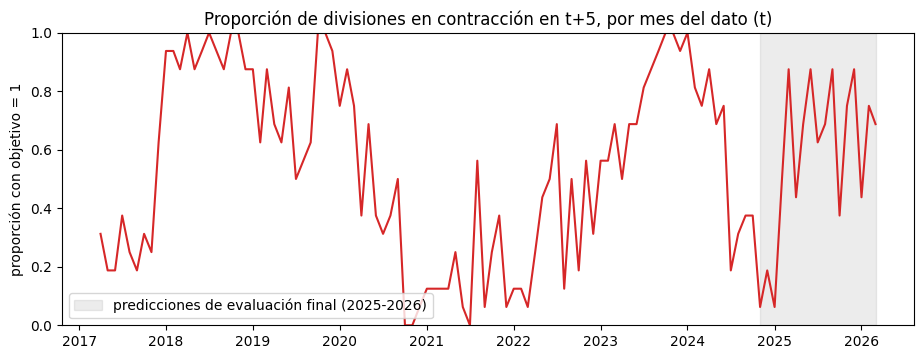

In [18]:
mensual = modelable.groupby("fecha")["objetivo"].mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(mensual.index, mensual.values, color="tab:red")
ax.axvspan(pd.Timestamp("2024-11-01"), mensual.index.max(), color="grey", alpha=0.15,
           label="predicciones de evaluación final (2025-2026)")
ax.set_ylabel("proporción con objetivo = 1")
ax.set_title("Proporción de divisiones en contracción en t+5, por mes del dato (t)")
ax.set_ylim(0, 1)
ax.legend(loc="lower left")
fig.savefig(FIGURES / "01_contraccion_por_mes.png", dpi=150, bbox_inches="tight")
plt.show()

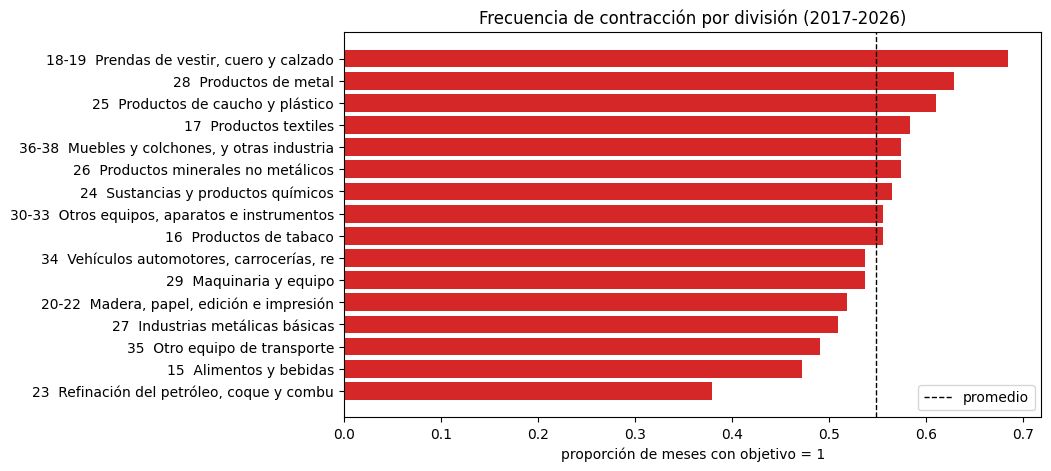

In [19]:
por_division = (modelable.groupby(["codigo_division", "division"])["objetivo"].mean()
                .sort_values().reset_index())
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(por_division["codigo_division"] + "  " + por_division["division"].str[:38],
        por_division["objetivo"], color="tab:red")
ax.axvline(modelable["objetivo"].mean(), color="black", linestyle="--", linewidth=1, label="promedio")
ax.set_xlabel("proporción de meses con objetivo = 1")
ax.set_title("Frecuencia de contracción por división (2017-2026)")
ax.legend()
fig.savefig(FIGURES / "02_contraccion_por_division.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Disponibilidad temporal y horizonte de predicción

**Horizonte (devolución de la Entrega 2).** El IPI del mes *t* se publica en el mes *t+2*: ese es el momento en que se toma la decisión. En la primera versión el objetivo era el mes *t+3*, que queda **un solo mes** después de la decisión. Para que la predicción anticipe de verdad **3 meses**, el objetivo pasa a ser el mes **t+5** (IPI de *t+5* contra *t-7*, el mismo mes del año anterior). Cada fila tiene:
- `mes_decision` = *t+2*: se publica el IPI de *t* y se hace la predicción. En ese momento ya están publicados el tipo de cambio, la BADLAR y la balanza comercial de *t*; la capacidad instalada se toma de *t-1* por prudencia.
- mes predicho = *t+5*: 3 meses después de la decisión.
- `mes_etiqueta_conocida` = *t+7*: se publica el IPI de *t+5* y se puede verificar si hubo contracción.

Para simular que estamos al comienzo de 2025, el entrenamiento solo puede incluir filas cuyo resultado se conocía **antes** de enero de 2025.

**Un mismo mes no se reparte entre entrenamiento y validación.** Todas las separaciones se hacen filtrando por fecha, nunca por posición de fila, así las 16 divisiones de un mes siempre quedan juntas.

**Predicciones sin resultado todavía.** Las filas de abril a agosto de 2026 quedan como *pendientes*: no se usan ni para entrenar ni para evaluar.

Ejemplo con una fila de diciembre de 2024:

In [20]:
tabla.loc[(tabla["fecha"] == "2024-12-01") & (tabla["codigo_division"] == "15"),
          ["fecha", "division", "mes_decision", "mes_etiqueta_conocida", "objetivo"]]

,fecha,division,mes_decision,mes_etiqueta_conocida,objetivo
107,2024-12-01,Alimentos y bebidas,2025-02-01,2025-07-01,0.0


El dato de diciembre de 2024 se publica en **febrero de 2025** (decisión). Se predice si **mayo de 2025** estará en contracción frente a mayo de 2024, es decir, 3 meses después de la decisión. El resultado recién se conoce en **julio de 2025**, cuando se publica el IPI de mayo. Esa fila **no** puede estar en el entrenamiento de un modelo que se usa desde enero de 2025.

Las funciones de `contraccion_industrial/modeling/particiones.py` aplican estas reglas:

In [21]:
from contraccion_industrial.modeling.particiones import separar_por_corte, cortes_validacion, comprobar_meses_enteros

entrenamiento, evaluacion, pendientes = separar_por_corte(con_historia, corte="2025-01-01")
resumen = pd.DataFrame({
    "filas": [len(entrenamiento), len(evaluacion), len(pendientes)],
    "meses": [c["fecha"].nunique() for c in (entrenamiento, evaluacion, pendientes)],
    "desde": [c["fecha"].min().strftime("%m/%Y") for c in (entrenamiento, evaluacion, pendientes)],
    "hasta": [c["fecha"].max().strftime("%m/%Y") for c in (entrenamiento, evaluacion, pendientes)],
}, index=["entrenamiento", "evaluación final", "pendientes"])
print("¿Algún mes repartido entre conjuntos?", not comprobar_meses_enteros(entrenamiento, evaluacion, pendientes))
resumen

¿Algún mes repartido entre conjuntos? False


,filas,meses,desde,hasta
entrenamiento,1376,86,04/2017,05/2024
evaluación final,272,17,11/2024,03/2026
pendientes,80,5,04/2026,08/2026


- **Entrenamiento:** datos de abril 2017 a mayo 2024. El último resultado conocido antes de enero 2025 es el de la fila de mayo 2024: el IPI de octubre 2024, publicado en diciembre 2024.
- **Evaluación final:** predicciones hechas desde enero de 2025 (datos de noviembre 2024 en adelante) cuyo resultado ya se observó, hasta la fila de marzo 2026 (IPI de agosto 2026).
- Las filas de junio a octubre de 2024 quedan afuera de ambos: sus predicciones se hicieron en 2024, pero sus resultados se conocieron recién en 2025. Con el horizonte más largo, este hueco pasa de 3 a 5 meses.

Para elegir modelos y variables se usa **validación temporal dentro del entrenamiento**, con la misma regla en cada corte. El corte de 2024 valida con menos filas (112) porque el entrenamiento termina en mayo 2024:

In [22]:
filas = []
for corte, ent, val in cortes_validacion(entrenamiento, ["2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"]):
    comprobar_meses_enteros(ent, val)
    filas.append({"corte": f"{corte:%m/%Y}", "entrenamiento hasta": f"{ent['fecha'].max():%m/%Y}",
                  "filas entrenamiento": len(ent),
                  "validación": f"{val['fecha'].min():%m/%Y} a {val['fecha'].max():%m/%Y}",
                  "filas validación": len(val)})
pd.DataFrame(filas)

,corte,entrenamiento hasta,filas entrenamiento,validación,filas validación
0,01/2021,05/2020,608,11/2020 a 10/2021,192
1,01/2022,05/2021,800,11/2021 a 10/2022,192
2,01/2023,05/2022,992,11/2022 a 10/2023,192
3,01/2024,05/2023,1184,11/2023 a 05/2024,112


## 6. Modelo de referencia

La referencia predice que **3 meses después de la decisión la división va a estar igual que en el último dato publicado**: si hoy está en contracción, predice contracción. Como cada fila representa el momento en que se publica el IPI de *t*, "hoy" es `contraccion_hoy` (IPI de *t* contra *t-12*), que es justamente la última situación conocida en `mes_decision`.

Su desempeño en los cortes de validación (dentro del entrenamiento) da la vara que tendrán que superar los modelos:

In [23]:
def metricas(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    vp = ((pred == 1) & (real == 1)).sum()
    fp = ((pred == 1) & (real == 0)).sum()
    fn = ((pred == 0) & (real == 1)).sum()
    precision = vp / (vp + fp) if vp + fp else np.nan
    recall = vp / (vp + fn) if vp + fn else np.nan
    return {"exactitud": (real == pred).mean(), "precisión": precision, "recall": recall,
            "F1": 2 * precision * recall / (precision + recall)}

filas = []
for corte, ent, val in cortes_validacion(entrenamiento, ["2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"]):
    filas.append({"corte": f"{corte:%m/%Y}", **metricas(val["objetivo"], val["contraccion_hoy"])})
referencia = pd.DataFrame(filas).set_index("corte")
referencia.loc["promedio"] = referencia.mean()
referencia.round(3)

,exactitud,precisión,recall,F1
corte,,,,
01/2021,0.740,0.211,0.286,0.242
01/2022,0.661,0.368,0.255,0.301
01/2023,0.547,0.734,0.527,0.613
01/2024,0.795,0.870,0.897,0.883
promedio,0.686,0.546,0.491,0.510


La referencia funciona muy bien cuando la industria está en una tendencia estable (corte 2024: F1 = 0,88, porque casi todas las divisiones siguen en contracción) y muy mal en los **cambios de ciclo** (cortes 2021 y 2022: F1 = 0,24 y 0,30, la salida de la recesión de 2020). El promedio es 0,51. Justamente en los cambios de ciclo es donde un modelo con información externa podría aportar, y con el horizonte de 3 meses desde la decisión esos cambios pesan más que con el horizonte anterior.

## 7. Relación entre predictoras y variable objetivo (solo entrenamiento)

Siguiendo la devolución, el objetivo acá es **explorar** la relación de cada variable con la contracción, no descartar variables: una variable puede aportar en combinación con otras aunque sola no muestre relación. Todo se calcula **solo con el conjunto de entrenamiento**, para no mirar 2025-2026 antes de la evaluación final.

Dos medidas simples por variable:
- **AUC univariada:** si se ordenaran las filas solo por esa variable, ¿qué tan bien separa contracción de no contracción? 0,5 = nada; cuanto más lejos de 0,5 (hacia arriba o hacia abajo), más información. Debajo de 0,5 indica relación inversa. Los empates reciben el rango promedio, así que valores iguales se tratan igual.
- **Tasa de contracción por quintil:** se divide la variable en 5 grupos según sus valores y se mira qué proporción de cada grupo termina en contracción.

**Corrección en la construcción de los quintiles (devolución de la Entrega 2).** La primera versión ordenaba con `rank(method="first")`, que da posiciones distintas a valores iguales según el orden de aparición. Como las variables macro (tipo de cambio, BADLAR, balanza y capacidad general) tienen el mismo valor para las 16 divisiones de un mes, eso podía mandar filas idénticas a quintiles distintos. Ahora:
- los **cortes se calculan sobre los valores originales** y cada fila cae en el intervalo que le corresponde, así que valores iguales siempre quedan en el mismo grupo; si hay empates en un corte, se aceptan **menos de 5 grupos**;
- para las **variables macro**, los cortes se calculan con **una observación por mes**, para que cada mes pese lo mismo y no se cuente 16 veces.

In [24]:
MACRO = ["uci_general", "uci_general_dif_ia", "tc_var_ia", "tc_var_3m",
         "badlar", "badlar_dif_ia", "expo_var_ia", "impo_var_ia"]   # un valor por mes

def auc_univariada(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    rangos = d["x"].rank()   # empates -> rango promedio
    n1, n0 = (d["y"] == 1).sum(), (d["y"] == 0).sum()
    return (rangos[d["y"] == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def tasa_por_quintil(datos, variable):
    """Tasa de contracción por quintil. Los cortes se calculan sobre los valores
    originales (con una observación por mes si la variable es macro); valores
    iguales caen siempre en el mismo intervalo y, si hay empates en los cortes,
    quedan menos de 5 grupos."""
    d = datos[["fecha", variable, "objetivo"]].dropna()
    base_cortes = d.groupby("fecha")[variable].first() if variable in MACRO else d[variable]
    cortes = np.unique(base_cortes.quantile([0, .2, .4, .6, .8, 1]).to_numpy())
    grupos = pd.cut(d[variable], bins=cortes, include_lowest=True,
                    labels=range(1, len(cortes)))
    return d.groupby(grupos, observed=True)["objetivo"].mean()

# Verificación: en cada mes, una variable macro cae en un único quintil para las 16 divisiones
for v in MACRO:
    d = entrenamiento[["fecha", v]].dropna()
    base_cortes = d.groupby("fecha")[v].first()
    cortes = np.unique(base_cortes.quantile([0, .2, .4, .6, .8, 1]).to_numpy())
    grupos = pd.cut(d[v], bins=cortes, include_lowest=True, labels=False)
    assert grupos.groupby(d["fecha"]).nunique().max() == 1, v
print("OK: ninguna variable macro separa un mismo mes en quintiles distintos")

exploracion = []
for v in PREDICTORAS:
    auc = auc_univariada(entrenamiento[v], entrenamiento["objetivo"])
    fila = {"variable": v, "AUC": auc, "distancia a 0,5": abs(auc - 0.5)}
    if entrenamiento[v].nunique() > 5:
        q = tasa_por_quintil(entrenamiento, v)
        fila["grupos"] = len(q)
        fila["contracción quintil más bajo"] = q.iloc[0]
        fila["contracción quintil más alto"] = q.iloc[-1]
    exploracion.append(fila)
exploracion = pd.DataFrame(exploracion).set_index("variable").sort_values("distancia a 0,5", ascending=False)
exploracion.round(3)

OK: ninguna variable macro separa un mismo mes en quintiles distintos


,AUC,"distancia a 0,5",grupos,contracción quintil más bajo,contracción quintil más alto
variable,,,,,
tc_var_ia,0.737,0.237,5.0,0.333,0.882
impo_var_ia,0.285,0.215,5.0,0.715,0.232
uci_general_dif_ia,0.286,0.214,5.0,0.743,0.309
ipi_var_ia,0.299,0.201,5.0,0.739,0.284
uci_bloque_dif_ia,0.312,0.188,5.0,0.731,0.271
ipi_var_ia_lag1,0.326,0.174,5.0,0.710,0.335
tc_var_3m,0.668,0.168,5.0,0.396,0.893
contraccion_hoy,0.654,0.154,NaN,NaN,NaN
badlar_dif_ia,0.647,0.147,5.0,0.431,0.702


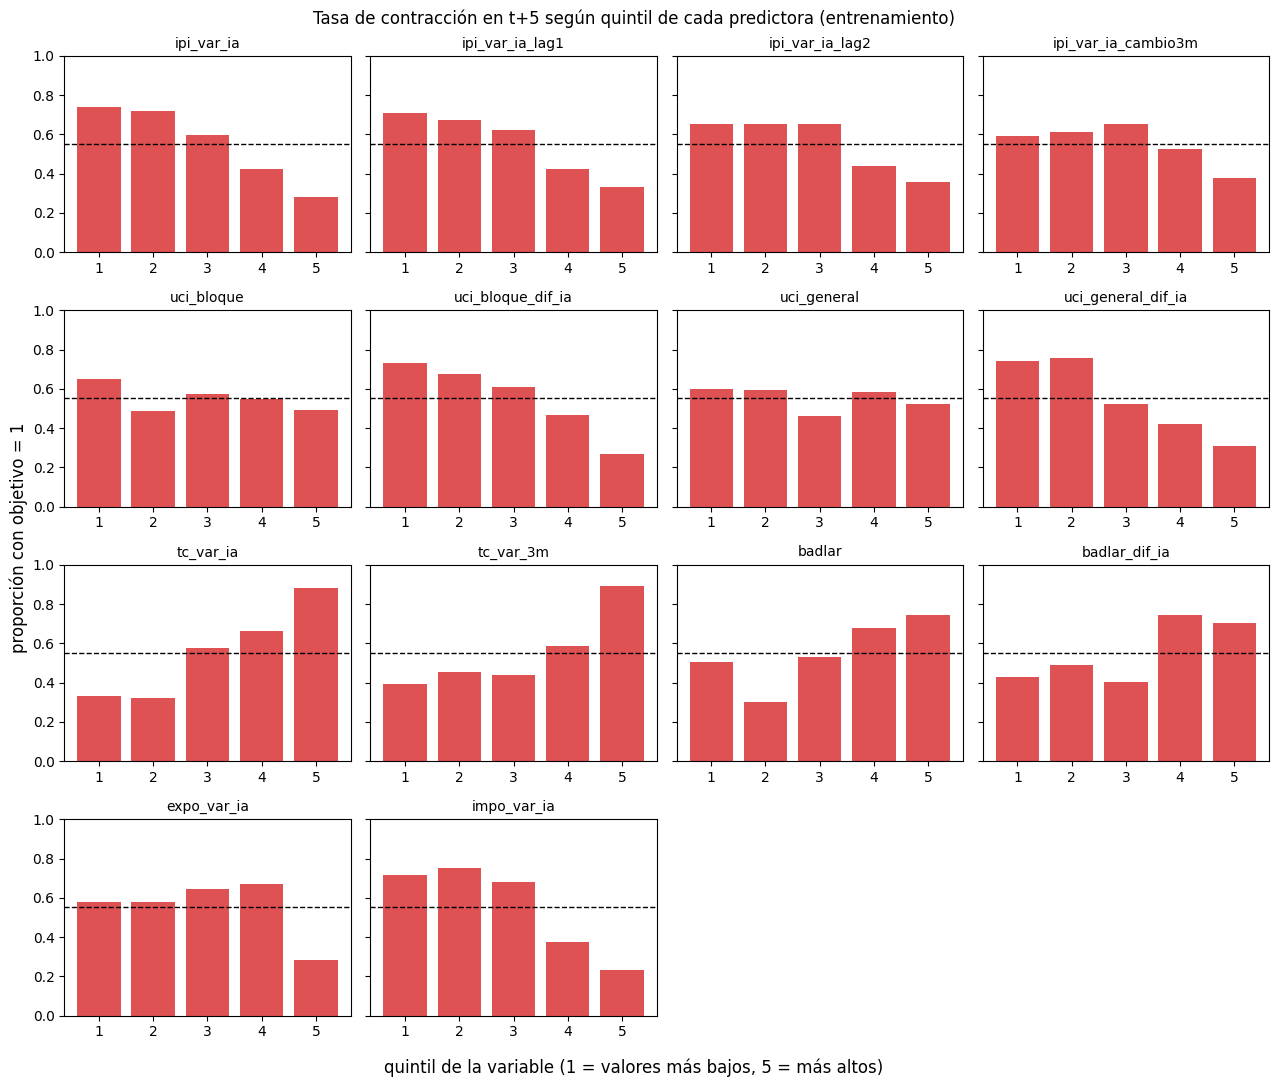

In [25]:
numericas = [v for v in PREDICTORAS if entrenamiento[v].nunique() > 5]
fig, ejes = plt.subplots(4, 4, figsize=(13, 11), sharey=True)
base = entrenamiento["objetivo"].mean()
for ax, v in zip(ejes.flat, numericas):
    q = tasa_por_quintil(entrenamiento, v)
    ax.bar(q.index.astype(str), q.values, color="tab:red", alpha=0.8)
    ax.axhline(base, color="black", linestyle="--", linewidth=1)
    ax.set_title(v, fontsize=10)
    ax.set_ylim(0, 1)
for ax in ejes.flat[len(numericas):]:
    ax.axis("off")
fig.supxlabel("quintil de la variable (1 = valores más bajos, 5 = más altos)")
fig.supylabel("proporción con objetivo = 1")
fig.suptitle("Tasa de contracción en t+5 según quintil de cada predictora (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES / "03_contraccion_por_quintil.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura de los resultados:**

- **Las variables del propio IPI** siguen siendo informativas: cuando la variación interanual actual está en el quintil más bajo, el 74% termina en contracción en *t+5*; en el más alto, el 28%. La señal se debilita con el rezago (AUC 0,30 → 0,33 → 0,37 de `ipi_var_ia` a `lag2`), así que lo más reciente pesa más. Con el horizonte más largo esta señal es algo más débil que con *t+3*, como era de esperar.
- **La capacidad instalada** informa a través de su **cambio interanual** (`uci_general_dif_ia` 0,29, `uci_bloque_dif_ia` 0,31) mucho más que por su **nivel** (AUC ≈ 0,46). Una capacidad que cae respecto al año anterior anticipa contracción.
- **Tipo de cambio**: su variación interanual es la variable con mayor AUC (0,74), y la de 3 meses también muestra relación (0,67): las devaluaciones fuertes preceden contracciones. Recordar que es una variación **nominal** (sección 2): parte de su señal puede reflejar episodios de inflación alta en general.
- **Importaciones**: su caída interanual se asocia a contracción (AUC 0,29), coherente con que la industria usa insumos importados.
- **BADLAR**: con el horizonte más largo muestra una relación moderada (AUC ≈ 0,65 en nivel y en diferencia interanual): tasas altas o en suba preceden contracciones.
- **Exportaciones** y la **aceleración** de la variación del IPI (`cambio3m`) muestran relaciones más débiles.

**Precaución importante:** las variables macro (tipo de cambio, tasa, balanza, capacidad general) tienen **un solo valor por mes**, igual para las 16 divisiones. Su relación con el objetivo se apoya en pocos episodios (las recesiones de 2018-2019 y 2023), así que su AUC está más expuesta al azar que la de las variables por división. La validación temporal va a mostrar si esa relación se sostiene fuera de los años en que se observó.

In [26]:
contraccion = entrenamiento.groupby("contraccion_hoy")["objetivo"].agg(["count", "mean"])
contraccion.index = ["no está en contracción hoy", "está en contracción hoy"]
contraccion.columns = ["filas", "proporción en contracción en t+5"]
contraccion.round(3)

,filas,proporción en contracción en t+5
no está en contracción hoy,661,0.393
está en contracción hoy,715,0.699


Estar en contracción hoy eleva la probabilidad de contracción en *t+5* del 39% al 70%: la inercia es fuerte, y por eso la referencia es exigente.

### ¿La capacidad instalada del bloque informa en todas las divisiones?

Se repite la AUC de `uci_bloque_dif_ia` división por división, para revisar en especial las asignaciones aproximadas (18-19 y 36-38).

In [27]:
por_div = (entrenamiento.groupby(["codigo_division", "bloque_capacidad"])
           .apply(lambda g: auc_univariada(g["uci_bloque_dif_ia"], g["objetivo"]), include_groups=False)
           .rename("AUC uci_bloque_dif_ia").reset_index())
por_div.round(3)

,codigo_division,bloque_capacidad,AUC uci_bloque_dif_ia
0,15,Productos alimenticios y bebidas,0.343
1,16,Productos del tabaco,0.472
2,17,Productos textiles,0.423
3,18-19,Productos textiles,0.209
4,20-22,Papel y cartón + Edición e impresión,0.336
5,23,Refinación del petróleo,0.380
6,24,Sustancias y productos químicos,0.431
7,25,Productos de caucho y plástico,0.362
8,26,Productos minerales no metálicos,0.218
9,27,Industrias metálicas básicas,0.350


### Correlación entre predictoras

Variables muy correlacionadas entre sí aportan información repetida. Esto es importante para la regresión logística (coeficientes inestables) y menos para los árboles.

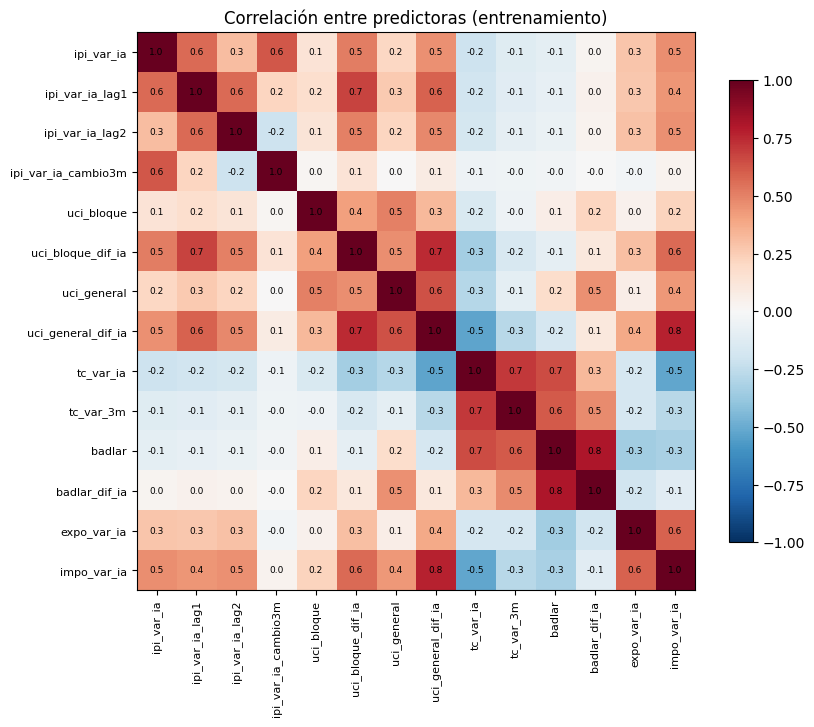

In [28]:
corr = entrenamiento[numericas].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)), numericas, rotation=90, fontsize=8)
ax.set_yticks(range(len(numericas)), numericas, fontsize=8)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación entre predictoras (entrenamiento)")
fig.savefig(FIGURES / "04_correlacion_predictoras.png", dpi=150, bbox_inches="tight")
plt.show()

In [29]:
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("correlación").reset_index())
pares.columns = ["variable 1", "variable 2", "correlación"]
pares["abs"] = pares["correlación"].abs()
pares.sort_values("abs", ascending=False).head(8).drop(columns="abs").round(2)

,variable 1,variable 2,correlación
85,badlar,badlar_dif_ia,0.81
75,uci_general_dif_ia,impo_var_ia,0.77
56,uci_bloque_dif_ia,uci_general_dif_ia,0.75
76,tc_var_ia,tc_var_3m,0.70
16,ipi_var_ia_lag1,uci_bloque_dif_ia,0.68
77,tc_var_ia,badlar,0.65
63,uci_general,uci_general_dif_ia,0.64
2,ipi_var_ia,ipi_var_ia_cambio3m,0.62


En la tabla por división, la capacidad del bloque tiene AUC menor a 0,5 (relación esperada: cae la capacidad, sigue contracción) en **las 16 divisiones**, aunque en **tabaco** (0,47) la relación es casi nula: es un sector pequeño, con pocas plantas, donde la capacidad se mueve por razones propias. Las asignaciones aproximadas muestran relación: **18-19** con el bloque textil da 0,21 (de las más fuertes) y **36-38** con el nivel general da 0,30. Como se aclaró en la sección 2, esto indica una asociación útil para predecir, no que los sectores sean equivalentes.

En las correlaciones, los pares más altos son BADLAR con su diferencia interanual (0,81), la capacidad general con las importaciones (0,77) y la capacidad del bloque con la general (0,75). Ninguna llega a ser redundante del todo, pero para la regresión logística convendrá no incluir todas juntas o usar regularización.

## 8. Preparación de las entradas para los modelos

Las predictoras están en escalas muy distintas: proporciones (variaciones interanuales, que en la pandemia llegan a +7,5), puntos porcentuales (capacidad instalada, BADLAR), niveles en % y una variable binaria. Para la **regresión logística** y, sobre todo, para **KNN**, que mide distancias, una variable con valores grandes dominaría a las demás:

In [30]:
pd.DataFrame({
    "mínimo": entrenamiento[PREDICTORAS].min(),
    "mediana": entrenamiento[PREDICTORAS].median(),
    "máximo": entrenamiento[PREDICTORAS].max(),
    "desvío": entrenamiento[PREDICTORAS].std(),
}).round(3)

,mínimo,mediana,máximo,desvío
ipi_var_ia,-0.886,-0.006,7.553,0.366
ipi_var_ia_lag1,-0.886,-0.006,7.553,0.365
ipi_var_ia_lag2,-0.886,-0.005,7.553,0.364
ipi_var_ia_cambio3m,-7.089,-0.011,7.393,0.453
contraccion_hoy,0.000,1.000,1.000,0.500
uci_bloque,0.000,59.200,97.100,13.147
uci_bloque_dif_ia,-58.600,-0.300,65.700,10.217
uci_general,42.000,63.750,69.600,5.258
uci_general_dif_ia,-19.600,0.350,21.200,6.042
tc_var_ia,0.066,0.524,3.490,0.730


**Cómo se escala sin usar información de validación ni de evaluación.** El escalado está dentro de un `Pipeline` de scikit-learn (`contraccion_industrial/modeling/preprocesamiento.py`): al entrenar con un corte, los parámetros del escalado (media y desvío) se calculan **solo con las filas de entrenamiento de ese corte**, y después se aplican sin cambios a la validación de ese corte. Los árboles, random forest y gradient boosting no necesitan escalado, así que su pipeline no lo incluye.

Se comprueba en los cuatro cortes de validación: el escalado aprende con tantas filas como tiene el entrenamiento de cada corte, y sus parámetros cambian de un corte a otro porque se recalculan cada vez.

In [31]:
from sklearn.linear_model import LogisticRegression
from contraccion_industrial.modeling.preprocesamiento import armar_pipeline

filas = []
for corte, ent, val in cortes_validacion(entrenamiento, ["2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"]):
    pipe = armar_pipeline(LogisticRegression(max_iter=1000), "logistica")
    pipe.fit(ent[PREDICTORAS], ent["objetivo"])
    esc = pipe.named_steps["escalado"]
    assert esc.n_samples_seen_ == len(ent)          # aprendió solo con el entrenamiento del corte
    pos = {v: i for i, v in enumerate(PREDICTORAS)}
    filas.append({"corte": f"{corte:%m/%Y}", "filas usadas para escalar": esc.n_samples_seen_,
                  "filas de validación": len(val),
                  "media ipi_var_ia": esc.mean_[pos["ipi_var_ia"]],
                  "desvío ipi_var_ia": esc.scale_[pos["ipi_var_ia"]],
                  "media tc_var_ia": esc.mean_[pos["tc_var_ia"]],
                  "desvío tc_var_ia": esc.scale_[pos["tc_var_ia"]]})
pd.DataFrame(filas).set_index("corte").round(3)

,filas usadas para escalar,filas de validación,media ipi_var_ia,desvío ipi_var_ia,media tc_var_ia,desvío tc_var_ia
corte,,,,,,
01/2021,608,192,-0.065,0.181,0.561,0.344
01/2022,800,192,0.011,0.454,0.529,0.309
01/2023,992,192,0.036,0.422,0.478,0.297
01/2024,1184,112,0.037,0.388,0.504,0.292


**Valores extremos de la pandemia.** No se recortan (ver sección 3). Pero conviene ver qué le hacen al escalado: el desvío estándar se calcula con todos los valores, así que unos pocos extremos lo agrandan y "aplastan" al resto de las filas. El escalado robusto (`RobustScaler`: resta la mediana y divide por el rango intercuartílico) no cambia los datos, pero define la escala con la parte central de la distribución.

Se compara, con el entrenamiento completo, cuánto ocupa el 50% central de las filas después de cada escalado (rango intercuartílico de los valores escalados) y dónde queda el valor máximo:

In [32]:
from sklearn.preprocessing import RobustScaler, StandardScaler

numericas_continuas = [v for v in PREDICTORAS if v != "contraccion_hoy"]
X = entrenamiento[numericas_continuas]
est = pd.DataFrame(StandardScaler().fit_transform(X), columns=numericas_continuas)
rob = pd.DataFrame(RobustScaler().fit_transform(X), columns=numericas_continuas)
rango_central = lambda d: d.quantile(0.75) - d.quantile(0.25)
comparacion = pd.DataFrame({
    "estándar: rango central": rango_central(est),
    "estándar: máximo": est.max(),
    "robusto: rango central": rango_central(rob),
    "robusto: máximo": rob.max(),
})
comparacion.sort_values("estándar: máximo", ascending=False).round(2).head(8)

,estándar: rango central,estándar: máximo,robusto: rango central,robusto: máximo
ipi_var_ia_lag2,0.44,20.68,1.0,46.68
ipi_var_ia_lag1,0.45,20.64,1.0,46.40
ipi_var_ia,0.45,20.61,1.0,45.53
ipi_var_ia_cambio3m,0.37,16.33,1.0,43.76
uci_bloque_dif_ia,0.93,6.50,1.0,6.93
tc_var_3m,0.60,5.34,1.0,9.37
tc_var_ia,0.83,3.77,1.0,4.91
expo_var_ia,1.02,3.56,1.0,3.59


Con el escalado estándar, el 50% central de las variables del IPI ocupa menos de media unidad, mientras que el rebote de abril 2021 queda a más de 20 desvíos: casi todas las filas quedan "apretadas" y, en KNN, sus diferencias pesarían poco frente a las de otras variables. Con el escalado robusto el 50% central ocupa una unidad en todas las variables, y los extremos quedan todavía más lejos (más de 40). Ninguno de los dos modifica los datos.

**Decisión:** el escalado estándar queda como opción por defecto, y el robusto se prueba como alternativa en la validación temporal (es un hiperparámetro más del pipeline). No se recortan valores: si la validación mostrara que los extremos perjudican a algún modelo, cualquier recorte se justificará y se calculará, como el escalado, solo con el entrenamiento de cada corte.

## 9. Resumen

**Dataset final** (`data/processed/tabla_modelo.csv`):
- **2.048 instancias** (16 divisiones × 128 meses, enero 2016 a agosto 2026).
- **Objetivo:** contracción interanual del mes *t+5* (IPI de *t+5* contra *t-7*), **3 meses después de la decisión** en *t+2*; el resultado se conoce en *t+7*.
- **Faltantes:** se excluyen enero-marzo 2017 (48 filas sin historia suficiente para rezagos y diferencias interanuales), sin imputar. Quedan **1.728 filas modelables** (abril 2017 a marzo 2026) **sin faltantes** en las predictoras.
- **24 columnas**: 4 de identificación, 3 de control temporal, 15 predictoras numéricas (14 continuas y una binaria) y la variable objetivo binaria.
- **Clases**: 54,9% de contracción en las filas modelables, con mucha variación entre años.

**Separación temporal:**
- Entrenamiento: 1.376 filas (04/2017 a 05/2024), solo con resultados conocidos antes de enero 2025.
- Evaluación final: 272 filas (predicciones de 2025-2026 con resultado observado).
- Pendientes: 80 filas (abril a agosto 2026), sin resultado todavía.
- Validación temporal con 4 cortes dentro del entrenamiento, sin repartir meses. Referencia: F1 promedio 0,51.

**Exploración (solo entrenamiento)**: las variables del IPI, el cambio interanual de la capacidad instalada, el tipo de cambio, las importaciones y la BADLAR muestran relación con la contracción en *t+5*. Con el horizonte más largo, las variables externas ganan peso frente a las del propio IPI: la variación interanual del tipo de cambio es ahora la de mayor AUC (0,74). Que aporten **más allá de la referencia** se evalúa en la próxima etapa.

**Preparación para los modelos**: escalado dentro de un pipeline, aprendido solo con el entrenamiento de cada corte (estándar por defecto, robusto como alternativa); los extremos de la pandemia se conservan.

**Próximos pasos:**
1. Entrenar los modelos (regresión logística, árbol, random forest, gradient boosting, KNN) con validación temporal.
2. Elegir hiperparámetros, tipo de escalado y variables dentro del entrenamiento, y comparar contra la referencia.
3. Evaluación final en 2025-2026.